# Density estimation and shear composition

Fit an unconditional affine coupling flow to generated two-moons coordinates, select its checkpoint using validation negative log likelihood (NLL), and evaluate the held-out test split after selection. Then compose the fitted flow with a volume-preserving shear to obtain a family of exact densities without retraining.

The default run is a **600-epoch demonstration** with patience 150, six coupling layers and hidden width 64. Its cosine schedule and training budget differ from the full experiment described in the README, so its metrics are reported separately. All splits contain generated data; class labels are only plot colours.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd() if (Path.cwd() / 'src' / 'moonflow').is_dir() else Path.cwd().parent
if not (ROOT / 'src' / 'moonflow').is_dir():
    raise RuntimeError('Start Jupyter in the repository root or notebooks directory.')
sys.path.insert(0, str(ROOT / 'src'))

import matplotlib.pyplot as plt
import torch

get_ipython().run_line_magic('matplotlib', 'inline')
torch.set_num_threads(1)
torch.manual_seed(42)
plt.rcParams.update({'font.size': 11, 'figure.dpi': 120})

import json
import os

from IPython.display import Image, display
from moonflow.data import load_moons_splits, make_moons_splits
from moonflow.pipeline import run_experiment
from moonflow.plotting import density_figure, shear_figure, training_figure
from moonflow.training import TrainConfig, evaluate_nll, fit, load_checkpoint
from moonflow.transforms import family_log_prob, g_alpha, g_alpha_inverse

QUICK_CONFIG = TrainConfig(max_epochs=600, patience=150)
RUN_TINY_FIT = True
EXISTING_RESULTS = os.environ.get('M2_RESULTS_DIR')
RESULTS_DIR = Path(EXISTING_RESULTS).expanduser() if EXISTING_RESULTS else ROOT / 'outputs' / 'notebook'
if not RESULTS_DIR.is_absolute():
    RESULTS_DIR = ROOT / RESULTS_DIR


## A small training check

Fit only the first 128 generated training points for 300 epochs. There is no validation selection in this diagnostic: it asks whether the optimiser can reduce the loss on a small sample. Its training loss is not a generalisation estimate, and it does not choose hyperparameters for the full run. Set `RUN_TINY_FIT = False` above to skip it.

Tiny-set training NLL: 2.8719 → 0.8642 nats / point


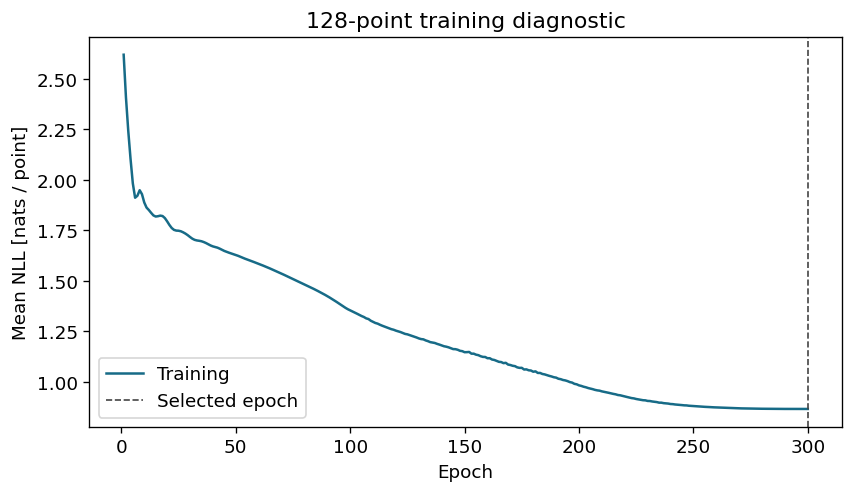

In [2]:
if RUN_TINY_FIT:
    tiny_points = make_moons_splits(seed=42)['train'].tensor()[:128]
    tiny_result = fit(tiny_points, None, TrainConfig(max_epochs=300, patience=None))
    print(f'Tiny-set training NLL: {tiny_result.initial_train_nll:.4f} → {tiny_result.train_nll:.4f} nats / point')
    tiny_figure = training_figure(tiny_result)
    tiny_figure.axes[0].set_title('128-point training diagnostic')
    plt.show()
else:
    print('Tiny-set training diagnostic skipped.')


## Train or inspect a saved experiment

With no environment setting, run the generated-data experiment and save results under `outputs/notebook/`. To inspect an existing experiment, set `M2_RESULTS_DIR` before starting Jupyter. A saved generated-data run contains its coordinate CSVs in `data/`; for a saved external-data run, also set `M2_DATA_DIR` to its input CSV directory. Relative environment paths are resolved from the repository root.

Training minimises mean NLL with full-batch Adam and cosine learning-rate decay. The checkpoint with the lowest validation NLL is restored, and only then is test NLL evaluated. A negative NLL is valid for continuous probability densities.

In [3]:
if EXISTING_RESULTS:
    summary = json.loads((RESULTS_DIR / 'summary.json').read_text())
    print('Loaded a saved experiment; no full-data training performed.')
else:
    summary = run_experiment(RESULTS_DIR, config=QUICK_CONFIG)
    print('Completed the 600-epoch demonstration budget.')

flow, fitted_config, checkpoint_metadata = load_checkpoint(RESULTS_DIR / 'flow.pt')
data_directory = Path(os.environ['M2_DATA_DIR']).expanduser() if os.environ.get('M2_DATA_DIR') else RESULTS_DIR / 'data'
if not data_directory.is_absolute():
    data_directory = ROOT / data_directory
splits = load_moons_splits(data_directory)
print(f"Data: {summary['data']['kind']}; sizes: {summary['data']['split_sizes']}")
print(f"Epochs run: {summary['epochs_run']}; selected epoch: {summary['best_epoch']}; budget: {fitted_config.max_epochs}")
for split, value in summary['nll_nats_per_point'].items():
    print(f'{split:10s} NLL: {value:.4f} nats / point')

for split, metric_name in (('train', 'train'), ('val', 'validation'), ('test', 'test')):
    measured = evaluate_nll(flow, splits[split].tensor())
    assert abs(measured - summary['nll_nats_per_point'][metric_name]) < 1e-6


Completed the 600-epoch demonstration budget.
Data: generated_two_moons; sizes: {'train': 800, 'val': 100, 'test': 100}
Epochs run: 320; selected epoch: 170; budget: 600
train      NLL: 1.0859 nats / point
validation NLL: 1.1478 nats / point
test       NLL: 1.1718 nats / point


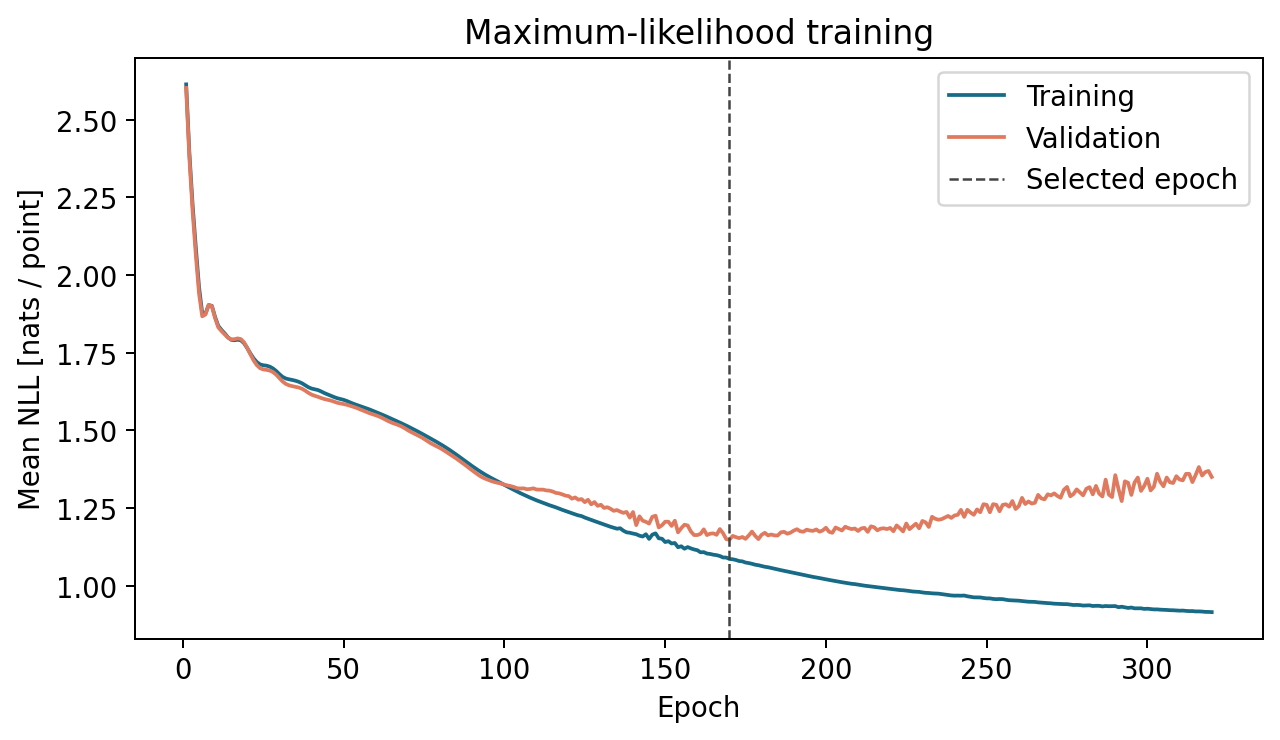

In [4]:
display(Image(filename=str(RESULTS_DIR / 'training.png')))


## Density and generated samples

The density is evaluated with the inverse map and its analytic Jacobian. Samples use an independent seeded Gaussian draw and the forward map. The class labels never enter either computation; this is a single density model for the whole distribution.

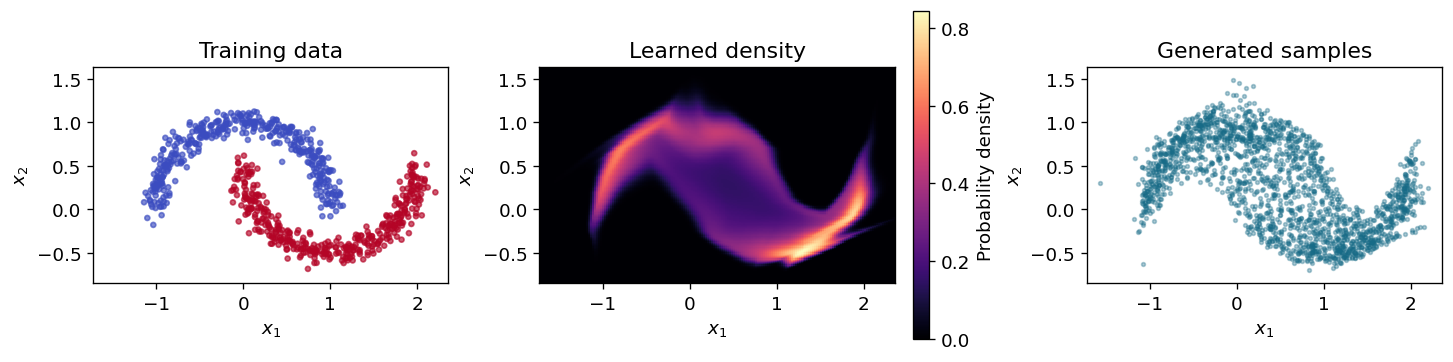

In [5]:
with torch.no_grad():
    samples = flow.sample(2000, generator=torch.Generator().manual_seed(2026))

density_figure(flow, splits['train'], samples)
plt.show()


## Compose with a shear

For $g_\alpha(x_1,x_2)=(x_1+\alpha x_2,x_2)$,

$$g_\alpha^{-1}(y_1,y_2)=(y_1-\alpha y_2,y_2),\qquad
J_{g_\alpha}=\begin{pmatrix}1&\alpha\\0&1\end{pmatrix},\qquad\det J_{g_\alpha}=1.$$

Therefore $f_\alpha=g_\alpha\circ f$ defines

$$\log p_\alpha(y)=\log p_X(g_\alpha^{-1}(y)).$$

The parameter $\alpha$ is a deterministic transformation coefficient, not a conditioning input learned by the network. Every panel below transforms the **same samples** to make the geometric comparison direct.

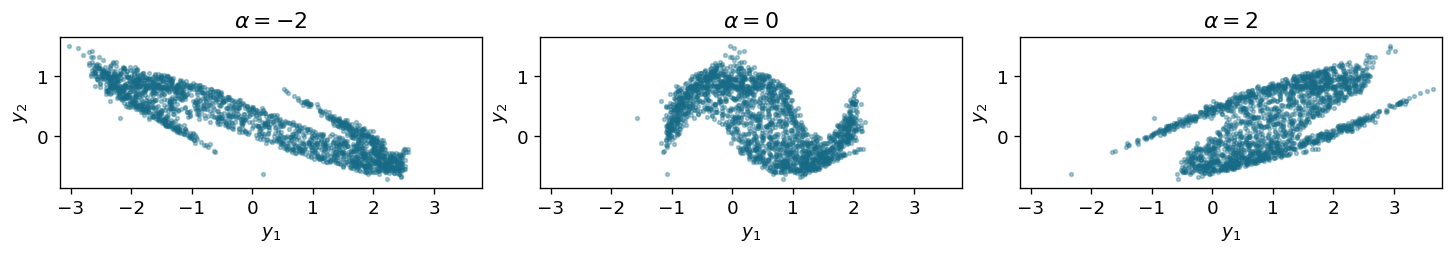

Shear round-trip maximum error: 2.384e-07
Density identity maximum error: 6.676e-06
Maximum absolute shear log-determinant: 0.0


In [6]:
shear_figure(samples, alphas=(-2.0, 0.0, 2.0))
plt.show()

alpha = 1.5
with torch.no_grad():
    transformed, shear_log_det = g_alpha(samples, alpha)
    recovered, _ = g_alpha_inverse(transformed, alpha)
    density_difference = (family_log_prob(flow, transformed, alpha) - flow.log_prob(samples)).abs()
print(f'Shear round-trip maximum error: {(recovered - samples).abs().max().item():.3e}')
print(f'Density identity maximum error: {density_difference.max().item():.3e}')
print(f'Maximum absolute shear log-determinant: {shear_log_det.abs().max().item():.1f}')


## What the experiment establishes

The validation checkpoint, held-out NLL, density map and generated samples describe this particular data generator, seed and training configuration. The exact shear identity follows from invertibility and unit determinant; it does not require fitting a second model. Finite-precision evaluations can have small residuals.

Some generated samples lie between the two arcs. This visual mismatch complements the held-out NLL and shows that the fitted density remains approximate.

The saved directory includes the checkpoint, configuration, split hashes, learning curves, numerical checks, samples and figures. For the full training command and external-data input schema, see [RUNNING.md](../RUNNING.md).